# Vision — Klasifikasi CNN (fine-tune)
**Kapan dipakai:** klasifikasi gambar dan embedding beku (`klasifikasi_embedding`) belum cukup
bagus, ada GPU, dan waktu cukup untuk melatih beberapa epoch.

**Langkah:** ResNet18 pretrained → lapisan terakhir diganti sesuai jumlah kelas → semua lapisan
dilatih ulang dengan loop training torch biasa (tanpa Trainer).

**Data demo:** CIFAR-10 kecil (gambar 32x32, 10 kelas).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from torch import nn
from torch.nn import functional
from torchvision import models

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/classification/cifar10_small"  # GANTI
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/test_labels.csv"   # hanya ada di data latihan
PRETRAINED = "../../pretrained"

PATH_COL = "path"     # path gambar, relatif terhadap DATA_FOLDER
TARGET = "label"
IMAGE_SIZE = 64
EPOCHS = 5
BATCH_SIZE = 64
LEARNING_RATE = 0.001
SEED = 42
torch.manual_seed(SEED)
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
MEAN = torch.tensor([0.485, 0.456, 0.406])
MEAN = MEAN.view(1, 3, 1, 1)      # normalisasi warna ImageNet
STD = torch.tensor([0.229, 0.224, 0.225])
STD = STD.view(1, 3, 1, 1)

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train.isna().sum())
print(train[TARGET].value_counts())
train.head()

train: (4000, 2) | test: (1000, 2)
path     0
label    0
dtype: int64
label
airplane      400
automobile    400
bird          400
cat           400
deer          400
dog           400
frog          400
horse         400
ship          400
truck         400
Name: count, dtype: int64


,path,label
0,train/airplane/0000.png,airplane
1,train/airplane/0001.png,airplane
2,train/airplane/0002.png,airplane
3,train/airplane/0003.png,airplane
4,train/airplane/0004.png,airplane


## Gambar ke tensor (diperbesar ke IMAGE_SIZE, dinormalisasi ImageNet)

In [4]:
def load_images(paths):
    arrays = []
    for path in paths:
        arrays.append(np.asarray(Image.open(f"{DATA_FOLDER}/{path}").convert("RGB")))
    X = torch.tensor(np.stack(arrays)).permute(0, 3, 1, 2)
    X = X.float() / 255
    X = functional.interpolate(X, size=IMAGE_SIZE, mode="bilinear")
    return (X - MEAN) / STD


X_all = load_images(list(train[PATH_COL]))
X_test = load_images(list(test[PATH_COL]))
print("train:", X_all.shape, "| test:", X_test.shape)

train: torch.Size([4000, 3, 64, 64]) | test: torch.Size([1000, 3, 64, 64])


## Split train / validasi
Label teks diubah jadi nomor kelas 0, 1, 2, … (torch butuh angka).

In [5]:
encoder = LabelEncoder()
y_numbers = encoder.fit_transform(train[TARGET])
y_all = torch.tensor(y_numbers)
train_rows, val_rows = train_test_split(np.arange(len(y_numbers)), test_size=0.2,
                                        stratify=y_numbers, random_state=SEED)
print("train:", len(train_rows), "| validasi:", len(val_rows))

train: 3200 | validasi: 800


## Model
Pilih SATU blok: hapus `#` di blok yang ingin dipakai, beri `#` pada blok resnet18.

In [6]:
def make_model():
    n_classes = len(encoder.classes_)
    net = models.resnet18(weights=None)
    net.load_state_dict(torch.load(f"{PRETRAINED}/resnet18/model.pth", map_location="cpu"))
    net.fc = nn.Linear(net.fc.in_features, n_classes)

    # net = models.efficientnet_b0(weights=None)
    # net.load_state_dict(torch.load(f"{PRETRAINED}/efficientnet_b0/model.pth"))
    # net.classifier[1] = nn.Linear(net.classifier[1].in_features, n_classes)

    # net = models.convnext_tiny(weights=None)
    # net.load_state_dict(torch.load(f"{PRETRAINED}/convnext_tiny/model.pth"))
    # net.classifier[2] = nn.Linear(net.classifier[2].in_features, n_classes)

    # net = models.resnet50(weights=None)
    # net.load_state_dict(torch.load(f"{PRETRAINED}/resnet50/model.pth"))
    # net.fc = nn.Linear(net.fc.in_features, n_classes)
    return net.to(DEVICE)


print(type(make_model()).__name__)

ResNet


## Latih (loop training torch)
Augmentasi: setengah batch dibalik kiri-kanan. Kelas tidak seimbang: hapus `#` di baris
`class_weight` supaya kelas yang jarang diberi bobot loss lebih besar.

In [7]:
class_weight = None
# class_weight = (1 / torch.bincount(y_all).float()).to(DEVICE)


def train_model(X_part, y_part):
    net = make_model()
    optimizer = torch.optim.Adam(net.parameters(), lr=LEARNING_RATE)
    for epoch in range(EPOCHS):
        net.train()
        order = torch.randperm(len(X_part))
        for start in range(0, len(order), BATCH_SIZE):
            batch_rows = order[start:start + BATCH_SIZE]
            batch = X_part[batch_rows]
            if torch.rand(1).item() < 0.5:
                batch = batch.flip(3)     # balik kiri-kanan
            output = net(batch.to(DEVICE))
            loss = functional.cross_entropy(output, y_part[batch_rows].to(DEVICE),
                                            weight=class_weight)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        print("epoch", epoch + 1, "loss", round(loss.item(), 4))
    return net


net = train_model(X_all[train_rows], y_all[train_rows])

epoch 1 loss 1.2083


epoch 2 loss 0.6752


epoch 3 loss 0.8507


epoch 4 loss 0.3931


epoch 5 loss 0.3419


## Evaluasi di validasi

F1 macro: 0.6681
              precision    recall  f1-score   support

    airplane       0.77      0.69      0.73        80
  automobile       0.66      0.90      0.76        80
        bird       0.57      0.76      0.65        80
         cat       0.72      0.26      0.39        80
        deer       0.56      0.76      0.65        80
         dog       0.60      0.36      0.45        80
        frog       0.86      0.68      0.76        80
       horse       0.59      0.84      0.69        80
        ship       0.78      0.86      0.82        80
       truck       0.89      0.70      0.78        80

    accuracy                           0.68       800
   macro avg       0.70      0.68      0.67       800
weighted avg       0.70      0.68      0.67       800



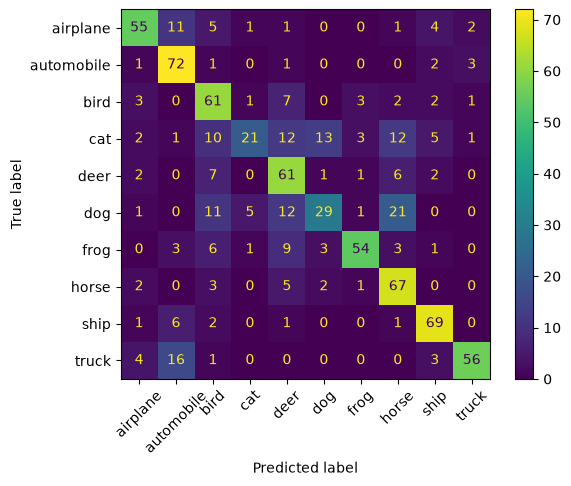

In [8]:
def predict_classes(net, X_part):
    net.eval()
    batches = []
    with torch.no_grad():
        for start in range(0, len(X_part), 256):
            output = net(X_part[start:start + 256].to(DEVICE))
            batches.append(output.argmax(1).cpu())
    return torch.cat(batches).numpy()


val_predictions = predict_classes(net, X_all[val_rows])
y_val = y_numbers[val_rows]
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions, target_names=encoder.classes_))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions, display_labels=encoder.classes_,
                                        xticks_rotation=45)
plt.show()

## Latih ulang di semua data + submission

In [9]:
net = train_model(X_all, y_all)
predictions = encoder.inverse_transform(predict_classes(net, X_test))

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

epoch 1 loss 1.1153


epoch 2 loss 1.2374


epoch 3 loss 0.4186


epoch 4 loss 0.3169


epoch 5 loss 1.2119


,id,label
0,1,truck
1,2,airplane
2,3,ship
3,4,airplane
4,5,airplane


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)

In [10]:
test_key = pd.read_csv(TEST_KEY_CSV)["label"]
print("F1 macro test:", round(f1_score(test_key, predictions, average="macro"), 4))

F1 macro test: 0.7068
